### Section 1: Data Loading

#### Cell 1 – Import Libraries

In [ ]:
!pip install -q kagglehub

import kagglehub
import os
import re
import html
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    TfidfVectorizer
)

from sklearn.model_selection import train_test_split

#### Cell 2 – Download Dataset

In [ ]:
path = kagglehub.dataset_download("hgultekin/bbcnewsarchive")

print("Dataset downloaded successfully!")
print("Dataset path:", path)

100%|██████████| 1.81M/1.81M [00:00<00:00, 36.3MB/s]

Extracting files...


Dataset downloaded successfully!
Dataset path: /root/.cache/kagglehub/datasets/hgultekin/bbcnewsarchive/versions/1


#### Cell 3 – Find and Load CSV

In [ ]:
csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("CSV files found:", csv_files)

df = pd.read_csv(
    csv_files[0],
    sep='\t',
    encoding='utf-8',
    engine='python'
)

print("Dataset loaded successfully!")

CSV files found: ['/root/.cache/kagglehub/datasets/hgultekin/bbcnewsarchive/versions/1/bbc-news-data.csv']
Dataset loaded successfully!


#### Cell 4 – Display First 5 Rows

In [ ]:
print("First 5 rows:")
display(df.head())

First 5 rows:


,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


#### Cell 5 – Dataset Overview

In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()

Dataset Shape: (2225, 4)

Column Names:
['category', 'filename', 'title', 'content']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   category  2225 non-null   object
 1   filename  2225 non-null   object
 2   title     2225 non-null   object
 3   content   2225 non-null   object
dtypes: object(4)
memory usage: 69.7+ KB


#### Cell 6 – Number of Samples and Classes

In [ ]:
print("Number of Samples:", df.shape[0])
print("Number of Columns:", df.shape[1])
label_column = "category"
print("\nNumber of Classes:", df[label_column].nunique())
print("\nClass Names:")
print(df[label_column].unique())

Number of Samples: 2225
Number of Columns: 4

Number of Classes: 5

Class Names:
['business' 'entertainment' 'politics' 'sport' 'tech']


#### Cell 7 – Missing Values

In [ ]:
print("Missing Values per Column:")
print(df.isnull().sum())
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values per Column:
category    0
filename    0
title       0
content     0
dtype: int64

Total Missing Values:
0


#### Cell 8 – Original Duplicate Rows

In [ ]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 0


#### Cell 9 – Original Category Distribution

In [ ]:
print("Number of News Articles in Each Category:")
category_counts = df['category'].value_counts()
display(category_counts)

Number of News Articles in Each Category:


,count
category,
sport,511
business,510
politics,417
tech,401
entertainment,386


#### Cell 10 – Visualize Category Distribution

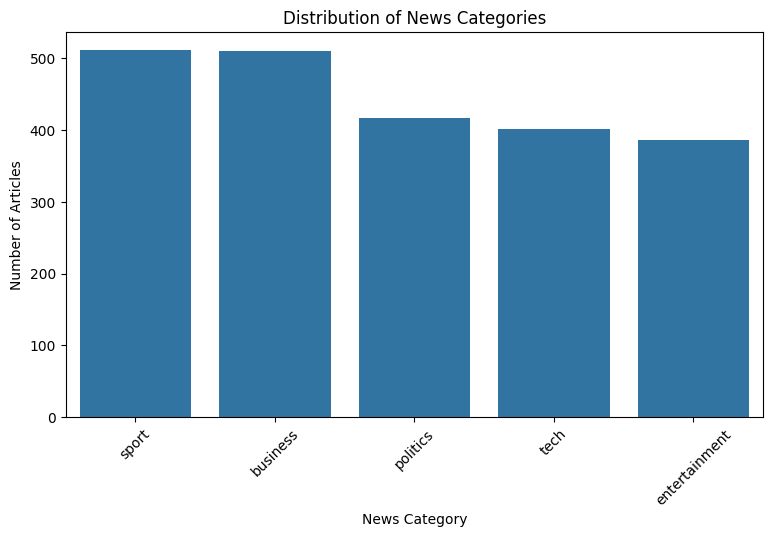

In [ ]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x='category',
    order=df['category'].value_counts().index
)
plt.title("Distribution of News Categories")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.show()

#### Cell 11 – Check Empty and Missing Text

In [ ]:
print("Empty Titles:", (df['title'].str.strip() == '').sum())
print("Empty Contents:", (df['content'].str.strip() == '').sum())
print("Missing Titles:", df['title'].isnull().sum())
print("Missing Contents:", df['content'].isnull().sum())

Empty Titles: 0
Empty Contents: 0
Missing Titles: 0
Missing Contents: 0


#### Cell 12 – Duplicate Text Analysis

In [ ]:
print("Duplicate Titles:", df['title'].duplicated().sum())
print("Duplicate Contents:", df['content'].duplicated().sum())
print(
    "Duplicate News (Title + Content):",
    df.duplicated(subset=['title', 'content']).sum()
)

Duplicate Titles: 129
Duplicate Contents: 133
Duplicate News (Title + Content): 98


#### Cell 13 – Text Length Analysis

In [ ]:
df['title_char_length'] = df['title'].str.len()
df['content_char_length'] = df['content'].str.len()
df['title_word_count'] = df['title'].str.split().str.len()
df['content_word_count'] = df['content'].str.split().str.len()
print("Text Length Statistics:")
display(
    df[
        [
            'title_char_length',
            'content_char_length',
            'title_word_count',
            'content_word_count'
        ]
    ].describe()
)

Text Length Statistics:


,title_char_length,content_char_length,title_word_count,content_word_count
count,2225.000000,2225.000000,2225.000000,2225.000000
mean,31.367191,2232.793258,5.204494,378.835955
std,2.605422,1364.249946,0.865494,238.220755
min,16.000000,471.000000,3.000000,84.000000
25%,31.000000,1414.000000,5.000000,240.000000
50%,32.000000,1936.000000,5.000000,326.000000
75%,33.000000,2774.000000,6.000000,466.000000
max,52.000000,25454.000000,9.000000,4428.000000


#### Cell 14 – Article Length Distribution

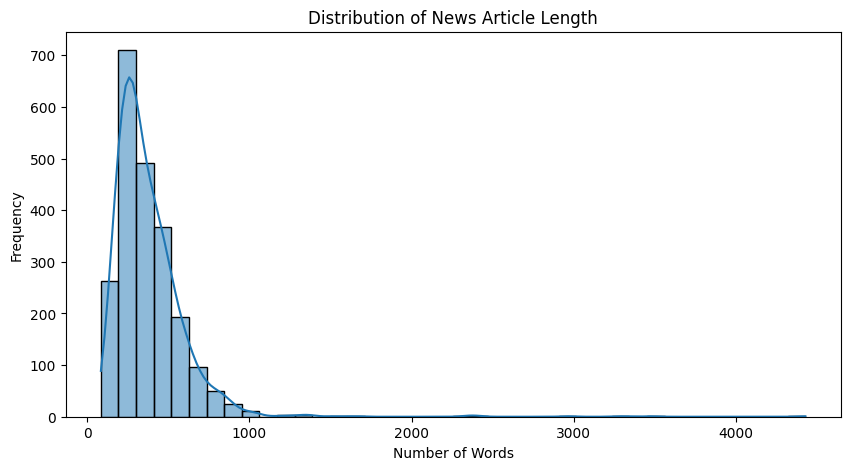

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x='content_word_count',
    bins=40,
    kde=True
)
plt.title("Distribution of News Article Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

#### Cell 15 – Average Article Length per Category

In [ ]:
category_length = df.groupby('category')['content_word_count'].mean()
print("Average Number of Words per Category:")
display(category_length)

Average Number of Words per Category:


,content_word_count
category,
business,323.484314
entertainment,325.196891
politics,448.884892
sport,324.369863
tech,497.428928


#### Cell 16 – Display Sample Articles

In [ ]:
for i in range(5):
    print("=" * 80)
    print("News Number:", i + 1)
    print("Category:", df.iloc[i]['category'])
    print("Title:", df.iloc[i]['title'])
    print("\nContent:")
    print(df.iloc[i]['content'])
    print("\n")

News Number: 1
Category: business
Title: Ad sales boost Time Warner profit

Content:
 Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.  The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.  Time Warner said on Friday that it now owns 8% of search-engine Google. But its own internet business, AOL, had has mixed fortunes. It lost 464,000 subscribers in the fourth quarter profits were lower than in the preceding three quarters. However, the company said AOL's underlying profit before exceptional items rose 8% on the back of stronger internet advertising revenues. It hopes to increase subscribers by offering the online service free to TimeWa

#### Cell 17 – Display One Article from Each Category

In [ ]:
for category in df['category'].unique():
    sample = df[df['category'] == category].sample(
        n=1,
        random_state=42
    ).iloc[0]
    print("=" * 80)
    print("Category:", category)
    print("Title:", sample['title'])
    print("\nContent:")
    print(sample['content'])
    print("\n")

Category: business
Title: Christmas sales worst since 1981

Content:
 UK retail sales fell in December, failing to meet expectations and making it by some counts the worst Christmas since 1981.  Retail sales dropped by 1% on the month in December, after a 0.6% rise in November, the Office for National Statistics (ONS) said. The ONS revised the annual 2004 rate of growth down from the 5.9% estimated in November to 3.2%. A number of retailers have already reported poor figures for December. Clothing retailers and non-specialist stores were the worst hit with only internet retailers showing any significant growth, according to the ONS.  The last time retailers endured a tougher Christmas was 23 years previously, when sales plunged 1.7%.  The ONS echoed an earlier caution from Bank of England governor Mervyn King not to read too much into the poor December figures. Some analysts put a positive gloss on the figures, pointing out that the non-seasonally-adjusted figures showed a performance 

#### Cell 18 – Check Duplicate News with Different Categories

In [ ]:
duplicate_news = df[
    df.duplicated(
        subset=['title', 'content'],
        keep=False
    )].sort_values(by=['title', 'category'])
print(
    "Number of rows involved in duplicate news:",
    len(duplicate_news)
)
display(
    duplicate_news[
        ['category', 'title', 'content']
    ].head(20)
)

Number of rows involved in duplicate news: 196


,category,title,content
1988,tech,'Brainwave' cap controls computer,A team of US researchers has shown that contr...
1989,tech,'Brainwave' cap controls computer,A team of US researchers has shown that contr...
954,politics,'Debate needed' on donations cap,A cap on donations to political parties shoul...
1193,politics,'Debate needed' on donations cap,A cap on donations to political parties shoul...
1003,politics,'Super union' merger plan touted,Two of Britain's big trade unions could merge...
1186,politics,'Super union' merger plan touted,Two of Britain's big trade unions could merge...
1949,tech,'Ultimate game' award for Doom 3,Sci-fi shooter Doom 3 has blasted away the co...
1994,tech,'Ultimate game' award for Doom 3,Sci-fi shooter Doom 3 has blasted away the co...
1992,tech,2D Metal Slug offers retro fun,"Like some drill sergeant from the past, Metal..."
2056,tech,2D Metal Slug offers retro fun,"Like some drill sergeant from the past, Metal..."


#### Cell 19 – Original Category Percentages

In [ ]:
print("Category Distribution:")
print(df['category'].value_counts())
print("\nCategory Percentages:")
print(
    (df['category'].value_counts(normalize=True) * 100).round(2)
)

Category Distribution:
category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64

Category Percentages:
category
sport            22.97
business         22.92
politics         18.74
tech             18.02
entertainment    17.35
Name: proportion, dtype: float64


#### Cell 20 – Check Conflicting Categories

In [ ]:
duplicate_groups = (
    df.groupby(['title', 'content'])['category']
    .nunique()
)
conflicting_news = duplicate_groups[duplicate_groups > 1]
print(
    "Number of news articles with conflicting categories:",
    len(conflicting_news)
)

Number of news articles with conflicting categories: 0


### Section 2: Data Cleaning

#### Cell 21 – Create Clean Dataset and Remove Duplicates


In [ ]:
df_clean = df.copy()
# Normalize extra whitespace in title and content
df_clean['title_clean'] = (
    df_clean['title']
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)
df_clean['content_clean'] = (
    df_clean['content']
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)
# Remove duplicates if either title OR content is repeated
duplicate_mask = (
    df_clean['title_clean'].duplicated(keep='first') |
    df_clean['content_clean'].duplicated(keep='first')
)
print("Duplicate rows to remove:", duplicate_mask.sum())
df_clean = df_clean[~duplicate_mask].copy()
print("\nShape after removing duplicates:", df_clean.shape)
print("\nCategory Distribution:")
print(df_clean['category'].value_counts())

Duplicate rows to remove: 165

Shape after removing duplicates: (2060, 10)

Category Distribution:
category
business         498
sport            489
politics         388
entertainment    362
tech             323
Name: count, dtype: int64


#### Cell 22 – Verify Clean Dataset

In [ ]:
print("Cleaned Dataset Shape:", df_clean.shape)
print("\nMissing Values:")
print(df_clean.isnull().sum())
print("\nCategory Distribution:")
print(df_clean['category'].value_counts())

Cleaned Dataset Shape: (2060, 10)

Missing Values:
category               0
filename               0
title                  0
content                0
title_char_length      0
content_char_length    0
title_word_count       0
content_word_count     0
title_clean            0
content_clean          0
dtype: int64

Category Distribution:
category
business         498
sport            489
politics         388
entertainment    362
tech             323
Name: count, dtype: int64


#### Cell 23 – Define Stopwords

In [ ]:
extra_stopwords = {
    "aren", "couldn", "didn", "doesn", "don", "hadn",
    "hasn", "haven", "isn", "ll", "mustn", "shouldn",
    "ve", "wasn", "weren", "wouldn"
}
stop_words = set(ENGLISH_STOP_WORDS) | extra_stopwords
print("Scikit-learn stopwords:", len(ENGLISH_STOP_WORDS))
print("Additional stopwords:", len(extra_stopwords))
print("Total unique stopwords:", len(stop_words))

Scikit-learn stopwords: 318
Additional stopwords: 16
Total unique stopwords: 334


#### Cell 24 – Define Text Cleaning Function


In [ ]:
def clean_text(title, content):
    # Step 1: Combine title + space + content
    text = str(title) + ' ' + str(content)

    # Step 2: Normalize extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    # Step 3: Decode HTML entities
    text = html.unescape(text)

    # Step 4: Remove HTML tags
    text = re.sub(r'<[^>]*>', ' ', text)

    # Step 5: Remove URLs
    text = re.sub(
        r'https?://\S+|www\.\S+',
        ' ',
        text,
        flags=re.IGNORECASE
    )

    # Step 6: Remove accents and non-ASCII characters
    text = unicodedata.normalize('NFKD', text)
    text = text.encode('ascii', 'ignore').decode('ascii')

    # Step 7: Convert to lowercase
    text = text.lower()

    # Step 8: Replace anything other than a-z with spaces
    text = re.sub(r'[^a-z]', ' ', text)

    # Step 9: Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    # Step 10: Remove words shorter than 2 characters
    words = [word for word in words if len(word) >= 2]

    # Normalize spaces
    return ' '.join(words)

#### Cell 25 – Golden Examples Test



In [ ]:
golden_examples = [
    {
        "input": (
            "<p>Shares in BBC's parent rose 12.5% to &#163;1.8m "
            "&amp; analysts don't expect more.</p>"
        ),
        "expected": "shares bbc parent rose analysts expect"
    },
    {
        "input": (
            "Jos&#233; Mourinho's side won 3-0; "
            "visit http://example.com/news now!"
        ),
        "expected": "jose mourinho won visit"
    },
    {
        "input": (
            "Mr Brown's U.S. budget deficit - worth "
            "$671.7bn (£484bn) - hit a record."
        ),
        "expected": "mr brown budget deficit worth bn bn hit record"
    },
    {
        "input": (
            "  They've said we'll see: TV, PC and EU rules "
            "for 2004-05 won't change.  "
        ),
        "expected": "said tv pc eu rules won change"
    },
    {
        "input": "&#163;1.8m indecency fine for Viacom",
        "expected": "indecency fine viacom"
    }
]

all_passed = True

for i, ex in enumerate(golden_examples):
    cleaned = clean_text("", ex["input"])

    if cleaned == ex["expected"]:
        print(f"Example {i+1}: PASS")
    else:
        print(
            f"Example {i+1}: FAIL "
            f"(Expected: '{ex['expected']}', Got: '{cleaned}')"
        )
        all_passed = False

if all_passed:
    print("\nOverall: 5/5 PASS")

Example 1: PASS
Example 2: PASS
Example 3: PASS
Example 4: PASS
Example 5: PASS

Overall: 5/5 PASS


#### Cell 26 – Apply Cleaning to All Articles

In [ ]:
# Apply cleaning to all articles
df_clean['text'] = df_clean.apply(
    lambda row: clean_text(
        row['title_clean'],
        row['content_clean']
    ),
    axis=1
)
print("Text cleaning completed successfully!")
print("\nOriginal Text:")
print(
    df_clean['title_clean'].iloc[0] + ' ' +
    df_clean['content_clean'].iloc[0][:300]
)
print("\nCleaned Text:")
print(df_clean['text'].iloc[0][:500])

Text cleaning completed successfully!

Original Text:
Ad sales boost Time Warner profit Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier. The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said four

Cleaned Text:
ad sales boost time warner profit quarterly profits media giant timewarner jumped bn months december year earlier firm biggest investors google benefited sales high speed internet connections higher advert sales timewarner said fourth quarter sales rose bn bn profits buoyed gains offset profit dip warner bros users aol time warner said friday owns search engine google internet business aol mixed fortunes lost subscribers fourth quarter profits lower preceding quarters company said aol underlying


#### Cell 27 – Vocabulary Before and After Cleaning

In [ ]:
# Vocabulary before cleaning
vocab_before = set(
    ' '.join(
        df_clean['title_clean'] + ' ' + df_clean['content_clean']
    ).lower().split()
)
# Vocabulary after cleaning
vocab_after = set(
    ' '.join(df_clean['text']).split()
)
print("Vocabulary before cleaning:", len(vocab_before))
print("Vocabulary after cleaning:", len(vocab_after))
print(
    "Vocabulary reduction:",
    len(vocab_before) - len(vocab_after)
)

Vocabulary before cleaning: 60466
Vocabulary after cleaning: 27516
Vocabulary reduction: 32950


#### Cell 28 – Create Model Dataset and Keep IDs

In [ ]:
df_clean['ID'] = (
    df_clean['category'] + '/' + df_clean['filename']
)
model_df = df_clean[
    ['ID', 'text', 'category']].copy()
X = model_df['text']
y = model_df['category']
print("Model Dataset Shape:", model_df.shape)
print("\nMissing Values:")
print(model_df[['text', 'category']].isnull().sum())
print("\nEmpty Cleaned Texts:", (X.str.len() == 0).sum())
print("\nDuplicate Cleaned Texts:", X.duplicated().sum())
print("\nCategory Distribution:")
print(y.value_counts())

Model Dataset Shape: (2060, 3)

Missing Values:
text        0
category    0
dtype: int64

Empty Cleaned Texts: 0

Duplicate Cleaned Texts: 0

Category Distribution:
category
business         498
sport            489
politics         388
entertainment    362
tech             323
Name: count, dtype: int64


### Section 3: Train / Validation / Test Split

#### Cell 29 – Split the Dataset

*Expected checkpoint:*
- Training samples: 1442
- Validation samples: 309
- Testing samples: 309
- Total samples: 2060

In [ ]:
# First split: 15% test, 85% remaining
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)
# Second split: 15% of the original dataset for validation
validation_ratio = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=validation_ratio,
    random_state=42,
    stratify=y_train_val
)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))
print(
    "\nTotal samples:",
    len(X_train) + len(X_val) + len(X_test)
)

Training samples: 1442
Validation samples: 309
Testing samples: 309

Total samples: 2060


#### Cell 30 – Check Class Distribution in Each Split

In [ ]:
print("Training distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nValidation distribution:")
print(y_val.value_counts(normalize=True).round(3))
print("\nTesting distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training distribution:
category
business         0.241
sport            0.237
politics         0.189
entertainment    0.176
tech             0.157
Name: proportion, dtype: float64

Validation distribution:
category
business         0.243
sport            0.239
politics         0.188
entertainment    0.175
tech             0.155
Name: proportion, dtype: float64

Testing distribution:
category
business         0.243
sport            0.236
politics         0.188
entertainment    0.175
tech             0.159
Name: proportion, dtype: float64


### Section 4: TF-IDF Feature Extraction

#### Cell 31 – Initialize and Fit TF-IDF

In [ ]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 1),
    min_df=3,
    max_df=0.8,
    max_features=None,
    sublinear_tf=True,
    stop_words=None
)
# Fit ONLY on training data
X_train_tfidf = tfidf.fit_transform(X_train)
# Transform validation and testing data
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

#### Cell 32 – Check TF-IDF Shapes and Number of Features

In [ ]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print(
    "\nNumber of learned features:",
    len(tfidf.get_feature_names_out())
)

Training TF-IDF shape: (1442, 9747)
Validation TF-IDF shape: (309, 9747)
Testing TF-IDF shape: (309, 9747)

Number of learned features: 9747


#### Cell 33 – Dataset and Feature Fingerprints

In [ ]:
import hashlib
import sklearn


def sha256_fingerprint(values):
    """
    Sort values, join them using a newline, and return
    the first 16 characters of the SHA-256 hash.
    """
    text = '\n'.join(sorted(map(str, values)))
    return hashlib.sha256(text.encode('utf-8')).hexdigest()[:16]


# Get IDs using the original model_df index
cleaned_ids = model_df.loc[X.index, 'ID']
train_ids = model_df.loc[X_train.index, 'ID']
val_ids = model_df.loc[X_val.index, 'ID']
test_ids = model_df.loc[X_test.index, 'ID']

# Fingerprints for dataset IDs
print("Dataset ID Fingerprints")
print("-" * 40)
print("Cleaned:", sha256_fingerprint(cleaned_ids))
print("Train:  ", sha256_fingerprint(train_ids))
print("Validation:", sha256_fingerprint(val_ids))
print("Test:   ", sha256_fingerprint(test_ids))

# Fingerprint for TF-IDF feature names
feature_names = tfidf.get_feature_names_out()

print("\nTF-IDF Feature Fingerprint")
print("-" * 40)
print("Feature fingerprint:", sha256_fingerprint(feature_names))

# Vocabulary size
print("\nTF-IDF Vocabulary Size")
print("-" * 40)
print("Number of features:", len(feature_names))

# Scikit-learn version
print("\nEnvironment")
print("-" * 40)
print("scikit-learn version:", sklearn.__version__)

Dataset ID Fingerprints
----------------------------------------
Cleaned: 28da125859a37dc3
Train:   8de979aeba4141ef
Validation: 49cbacb9cd34ead5
Test:    9df86829f9fed890

TF-IDF Feature Fingerprint
----------------------------------------
Feature fingerprint: b1a7493095743237

TF-IDF Vocabulary Size
----------------------------------------
Number of features: 9747

Environment
----------------------------------------
scikit-learn version: 1.6.1
